# 12. Лабораторная: проверить весь путь на известной поверхности

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** самостоятельно сравнить методы на общей правде, написать критерии приемки и разобрать ошибку по этапам.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Сначала сформулировать эксперимент

Проверяем не факт возврата массива, а восстановление заданной величины.
Записываем: N — периоды OPD; φ=2πN; λ=10600 nm; нормальное отражение h=λN/2;
X вправо, Y вверх; неизменная круглая апертура; стабильные a(x,y),b(x,y).
В этих уроках пиксели соответствуют единственной скалярной фазе: реальный спекл
и нелинейная оптика в этот исходный эксперимент не входят.

Сравниваются: Фурье, вейвлет по X, известные сдвиги PSI, уточнение сдвигов,
интерполяция **идеальных** контуров. Последний вариант отделяет ошибку интерполяции
от ошибки трассировки; он не подтверждает качество трассировщиков приложения.

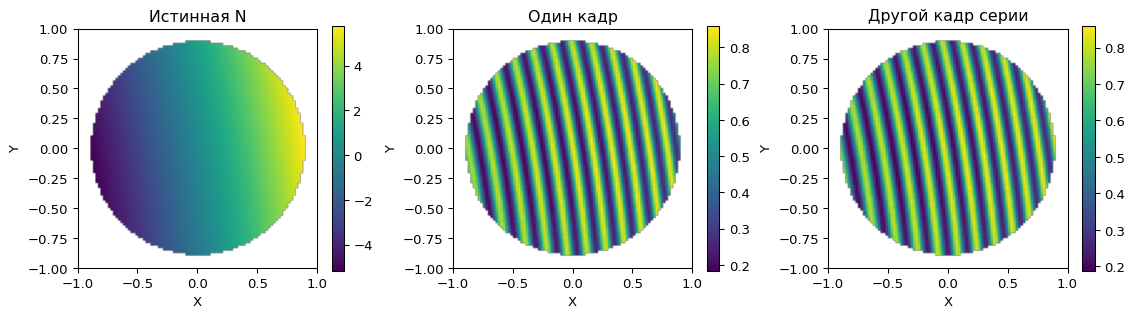

In [2]:
n=96
wavelength_nm=10600.
s=cl.scene(n=n,carrier_x=12,carrier_y=2,bowl=.3,astig=.08)
mask=s['mask']; roi=mask&(s['x']**2+s['y']**2<.5**2)
true_shifts=np.deg2rad([0,75,170,260,345])
nominal=np.arange(5)*np.pi/2
photons=15000
single=cl.camera(s['image'],photons=photons,bits=8,seed=100)
stack=np.array([cl.camera(s['a']+s['b']*np.cos(s['phi']+d),photons=photons,bits=8,seed=101+i)
                for i,d in enumerate(true_shifts)])
cl.show_maps([s['orders'],single,stack[1]],['Истинная N','Один кадр','Другой кадр серии'],mask)

## 2. Независимые пути восстановления

Не исправляем неверный знак выбором лучшего совпадения с правдой: для этого
эксперимента заранее выбрана положительная X-несущая и известен знак δ.
Удаляем из ошибки только общий пистон. Для полноты отдельно печатаем покрытие,
потому что маленькая ошибка на 10% поля не заменяет полноценную карту.

In [3]:
maps={}
ft=cl.fourier_phase(single,mask)
maps['Fourier']=ft['phi']/cl.TAU
cwt,quality=cl.cwt_phase(single,mask,np.geomspace(4,16,18),axis=1)
maps['CWT-X']=cwt/cl.TAU
known=cl.psi_known(stack,true_shifts,mask)
known_unwrapped,_=cl.unwrap_quality(known['phi'],np.where(mask,1,0),mask)
maps['PSI-known']=known_unwrapped/cl.TAU
unknown=cl.psi_unknown(stack,nominal,mask,max_iterations=100)
unknown_unwrapped,_=cl.unwrap_quality(unknown['phi'],np.where(mask,1,0),mask)
maps['PSI-refine']=unknown_unwrapped/cl.TAU
print('Уточнение δ: сошлось=',unknown['converged'],
      'ошибка сдвигов, градусы=',np.rad2deg(cl.wrap(unknown['shifts']-true_shifts)))

Уточнение δ: сошлось= False ошибка сдвигов, градусы= [ 0.       2.75832 -0.16948  2.81708  0.04624]


**Чтение диагностики PSI-refine.** Лимит в 100 итераций выбран намеренно небольшим. Если напечатано `сошлось=False`, полученная карта — промежуточный результат; она может уступать PSI с известными сдвигами. В итоговом отчёте зафиксируйте этот статус. Проверьте влияние лимита и начальных сдвигов, прежде чем сравнивать предельную точность методов.

## 3. Идеальные контуры — контроль самой интерполяции

На строке с известным Y наше поле имеет вид
$N(X)=AX^2+BX+C(Y)$, где A=bowl+astig, B=carrier_x/2.
Для каждого целого k решим AX²+BX+C−k=0 и оставим корень внутри апертуры.
Натуральный сплайн строится между найденными пересечениями; за крайними узлами
в этой лабораторной оставляем отсутствие данных. Так экстраполяция не прячется
в метрике восстановления.

In [4]:
axis=np.linspace(-1,1,n)
contour_map=np.full((n,n),np.nan)
A=.3+.08; B=12/2
levels=np.arange(np.floor(s['orders'][mask].min()),np.ceil(s['orders'][mask].max())+1)
for row,Y in enumerate(axis):
    C0=2*Y/2+(.3-.08)*Y*Y
    discriminant=B*B-4*A*(C0-levels)
    valid=discriminant>0
    roots=(-B+np.sqrt(discriminant[valid]))/(2*A)
    values=levels[valid]
    inside=roots*roots+Y*Y<.9**2
    roots,values=roots[inside],values[inside]
    if len(roots)<2: continue
    order=np.argsort(roots); roots,values=roots[order],values[order]
    use=mask[row]&(axis>=roots[0])&(axis<=roots[-1])
    contour_map[row,use]=interpolate.CubicSpline(roots,values,bc_type='natural')(axis[use])
maps['Ideal contours + spline']=contour_map

## 4. Метрики, которые не меняют предмет измерения

Для каждого метода печатаем RMS ошибки N, PV ошибки и долю покрытой апертуры.
Высотная ошибка для данного отражательного опыта равна λ/2 от ошибки N.
Это не RMS остатка после удаления всех аберраций: такую операцию надо оговаривать
отдельно. Для сравнения алгоритмов сначала используем одинаковую заранее заданную
центральную область, затем исследуем всё поле.

Метод                            RMS N     RMS h,nm       PV N   Покрытие поля
Fourier                       0.000330        1.749   0.002049           1.000
CWT-X                         0.001016        5.385   0.006069           1.000
PSI-known                     0.002011       10.659   0.014908           1.000
PSI-refine                    0.003448       18.275   0.018810           1.000
Ideal contours + spline       0.000041        0.220   0.000400           0.881


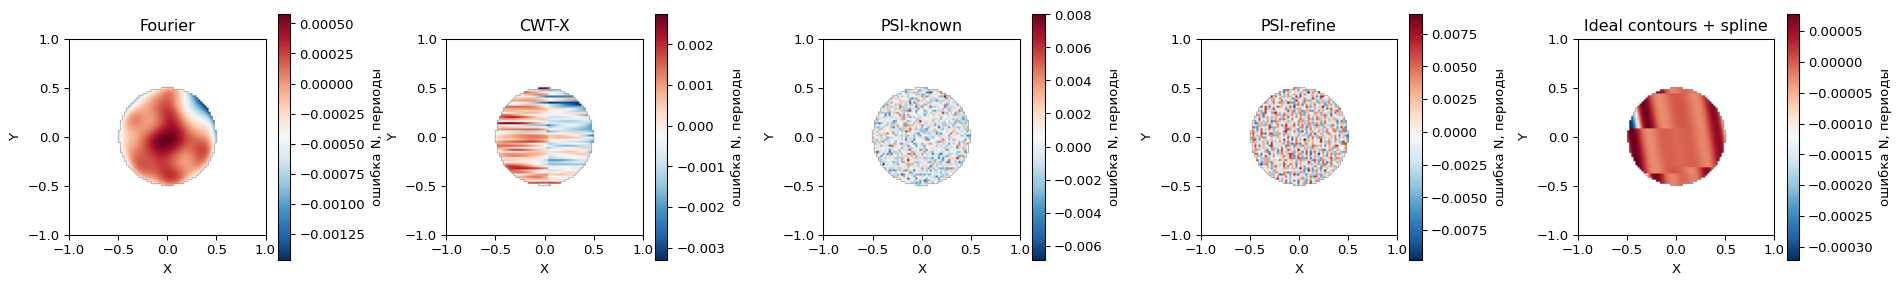

In [5]:
errors=[]; titles=[]
print(f'{"Метод":27s} {"RMS N":>10s} {"RMS h,nm":>12s} {"PV N":>10s} {"Покрытие поля":>15s}')
for name,prediction in maps.items():
    error,stats=cl.compare(prediction,s['orders'],roi)
    coverage=(np.isfinite(prediction)&mask).sum()/mask.sum()
    print(f'{name:27s} {stats["rms"]:10.6f} {stats["rms"]*wavelength_nm/2:12.3f} {stats["pv"]:10.6f} {coverage:15.3f}')
    errors.append(error); titles.append(name)
cl.show_maps(errors,titles,roi,cmap='RdBu_r',units='ошибка N, периоды')

## 5. Простая серия испытаний по шуму

Один красивый пример — недостаточное основание для выбора метода. Варьируем
число фотонов и повторяем шум с несколькими seed. Интерпретируем результат только
в пределах выбранной модели, геометрии и области оценки.
В обычной шумовой области ожидаем спад приблизительно как P⁻¹/²; затем может
появиться полка от фильтрации, квантования или систематической ошибки.

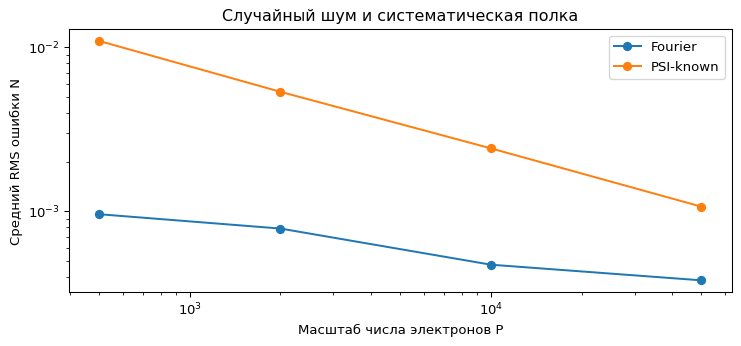

In [6]:
photon_counts=[500,2000,10000,50000]
fourier_errors=[]; psi_errors=[]
for P in photon_counts:
    ef=[]; ep=[]
    for seed in range(3):
        noisy=cl.camera(s['image'],photons=P,bits=12,seed=300+seed)
        output=cl.fourier_phase(noisy,mask)
        ef.append(cl.compare(output['phi']/cl.TAU,s['orders'],roi)[1]['rms'])
        frames=np.array([cl.camera(s['a']+s['b']*np.cos(s['phi']+d),photons=P,bits=12,seed=400+20*seed+i)
                         for i,d in enumerate(true_shifts)])
        fitted=cl.psi_known(frames,true_shifts,mask)
        phi,_=cl.unwrap_quality(fitted['phi'],np.ones(mask.shape),mask)
        ep.append(cl.compare(phi/cl.TAU,s['orders'],roi)[1]['rms'])
    fourier_errors.append(np.mean(ef)); psi_errors.append(np.mean(ep))
plt.loglog(photon_counts,fourier_errors,'o-',label='Fourier')
plt.loglog(photon_counts,psi_errors,'o-',label='PSI-known')
plt.xlabel('Масштаб числа электронов P'); plt.ylabel('Средний RMS ошибки N')
plt.legend(); plt.title('Случайный шум и систематическая полка'); plt.show()

## 6. Минимальные критерии приёмки алгоритма

1. Линейная фаза: знак, масштаб и ориентация осей заданы заранее.
2. Чётный/нечётный размер: нет искусственного скачка ошибки.
3. Горизонтальные/вертикальные/диагональные полосы: поддержка явно проверена или отказ объяснён.
4. Нет модуляции: алгоритм не выдумывает уверенную фазовую поверхность.
5. Кольцевая и разорванная апертура: маски корректны, число компонент известно.
6. Неверные сдвиги, фон, насыщение: измеряется систематическая ошибка, а не только сходимость.
7. Смена нормировки: карта/остаток неизменны, коэффициенты преобразованы согласованно.
8. Реальные данные: нужен независимый эталон, повторяемость и бюджет погрешностей.

Ни один фиксированный порог из этого курса не является техническим допуском стенда.
Для прибора надо задать допустимую ошибку поверхности, пространственное разрешение,
область измерения, диапазон наклонов/контраста и вероятность отказа.

In [7]:
for size in [95,96]:
    test=cl.scene(n=size,carrier_x=12,carrier_y=2)
    restored=cl.fourier_phase(test['image'],test['mask'])
    center=test['mask']&(test['x']**2+test['y']**2<.5**2)
    assert cl.compare(restored['phi']/cl.TAU,test['orders'],center)[1]['rms']<.05
try:
    cl.fourier_phase(np.ones((32,32)),np.ones((32,32),bool))
    raise AssertionError('Однотонный кадр не должен пройти')
except ValueError:
    print('Базовые проверки чётности и отсутствия контраста пройдены.')

Базовые проверки чётности и отсутствия контраста пройдены.


## Самостоятельный проект

Создайте свой вариант этой тетради и сдайте себе отчёт из четырёх частей:

1. **Модель:** λ, схема прохода, φ, a,b, шум, маска, сдвиги, система координат.
2. **Гипотеза:** что должно измениться при выбранном возмущении и почему.
3. **Результат:** карты ошибки, покрытие, RMS/PV до и после строго указанных удаляемых мод.
4. **Вывод:** что подтверждено, где метод отказал и какая информация остаётся неопределённой.

Варианты: центральное экранирование; кольцевые полосы без несущей; недостающая
полоса при трассировке; MinMax с шагом 1 вместо 1/2; неверный знак δ; сдвиг кадров
на долю пикселя; изменение усиления камеры; переменный фон; поле с разрывом высоты.

<details><summary>Как оценивать свой отчёт</summary>

Хороший отчёт позволяет другому человеку воспроизвести эксперимент из записанных
параметров. Нельзя выбирать знак/маску/удалённые термы после просмотра ошибки
и затем скрывать этот выбор. Отличайте доказательство на заданной модели,
сравнение с эталоном и проверку применимости модели к реальному измерению.
</details>

Теперь вернитесь к C++: проследите один пиксель и одну полосу через `SetupStage`,
`PhaseReconstructionStage`, S4 и S5. Для каждого перехода подпишите величину,
единицы, маску, координаты и принятые допущения. Это итоговая проверка понимания курса.